# Transformer (Sentence-Embedding) Approach for Complaint Category Classification

**Team project:** classify e-commerce customer-support complaints into 16 `Category` labels, two ways, compared head-to-head:

1. **Classical baseline** (teammate's notebook) — TF-IDF → Logistic Regression
2. **Transformer approach** (this notebook) — pre-trained sentence-transformer embeddings → **the same Logistic Regression classifier**

**Research question:** is the transformer's extra accuracy (if any) worth its extra compute cost, especially on rare/overlapping categories?

**Dataset:** `ecommerce_customer_support_cleaned.csv` — the team's shared cleaned file (same source as [`Ataur77/ecommerce-customer-support`](https://huggingface.co/datasets/Ataur77/ecommerce-customer-support) on Hugging Face), 1,334 complaints, 16 `Category` labels.

**Fairness rules used in this notebook (must match the baseline notebook exactly):**
- One shared 80/20 stratified split, `random_state=42`, stratified on `Category`
- All 16 `Category` labels kept unmerged (no grouping rare classes together)
- **Macro F1** is the primary metric (treats every class equally, so rare classes aren't hidden by accuracy)
- Compute cost (embedding time, training time, inference latency, memory) is tracked alongside accuracy


## 1. Imports

In [1]:
import time
import json
import pickle
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psutil
import os

from sentence_transformers import SentenceTransformer

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score, accuracy_score, classification_report,
    confusion_matrix
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries loaded.")


Libraries loaded.


## 2. Load Dataset

Loading the team's shared cleaned CSV (`ecommerce_customer_support_cleaned.csv`) — same source data as [`Ataur77/ecommerce-customer-support`](https://huggingface.co/datasets/Ataur77/ecommerce-customer-support) on Hugging Face, already cleaned. Using this local file (instead of re-downloading from the Hub) keeps things simple and guarantees every teammate's notebook is reading the exact same rows in the exact same order — which matters for the shared train/test split below.

In [2]:
df = pd.read_csv('../data/ecommerce_customer_support_cleaned.csv')

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head(3)


Shape: (1334, 3)
Columns: ['Complaint', 'Category', 'Urgency']


,Complaint,Category,Urgency
0,I can’t add a new address — button does nothing.,Account & Shipping,Low
1,Flash sale prices aren’t reflected during chec...,Promotions,Immediate
2,System declined my payment without any reason....,Payments,Immediate


## 3. Quick Sanity Check

(Full EDA is a teammate's part of the project — this is just enough to confirm the data matches spec: 16 categories, no nulls, no duplicates.)

In [3]:
print("Unique categories:", df['Category'].nunique())
print()
print("Category distribution:")
print(df['Category'].value_counts())
print()
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())


Unique categories: 16

Category distribution:
Category
Promotions            137
Order Tracking        130
Payments              120
Shipping              108
Account               106
Product Quality       105
Special Requests      104
Inventory             103
Returns                99
Checkout               98
Subscriptions          97
Product Issues         29
Order Issues           29
Technical Issues       25
Account & Shipping     24
Refunds                20
Name: count, dtype: int64

Missing values:
 Complaint    0
Category     0
Urgency      0
dtype: int64
Duplicate rows: 0


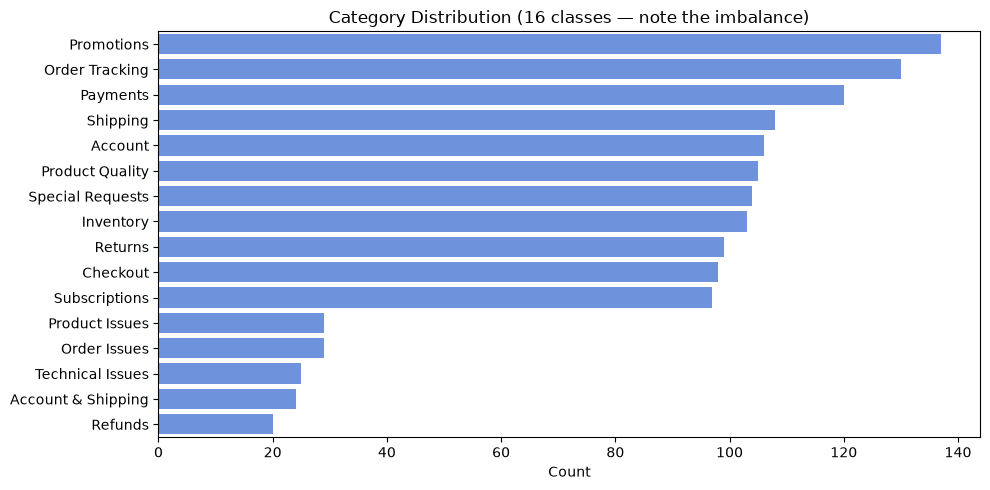

In [4]:
plt.figure(figsize=(10, 5))
order = df['Category'].value_counts().index
sns.countplot(y='Category', data=df, order=order, color='#5B8DEF')
plt.title('Category Distribution (16 classes — note the imbalance)')
plt.xlabel('Count')
plt.ylabel('')
plt.tight_layout()
plt.show()


## 4. Shared Train/Test Split

This split **must be identical to the baseline notebook's split** — same rows in train, same rows in test — otherwise the comparison isn't fair.

Rule: 80/20, stratified on `Category`, `random_state=42`. Since both notebooks load the same dataset in the same row order and apply `train_test_split` with these exact same parameters, the split will match. We also save the split to disk so the team can double-check row-for-row.

In [5]:
# Cast to plain numpy object arrays — pandas' Arrow-backed string dtype
# (default for datasets loaded via the `datasets` library) doesn't play well
# with sklearn's fancy indexing, so we convert explicitly.
X = df['Complaint'].astype(str).to_numpy(dtype=object)
y = df['Category'].astype(str).to_numpy(dtype=object)

X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, np.arange(len(df)),
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Train size: {len(X_train)}")
print(f"Test size:  {len(X_test)}")

# Save the split indices so teammates can verify/reuse the exact same split
split_dir = '../data/shared_split'
os.makedirs(split_dir, exist_ok=True)
pd.DataFrame({'index': idx_train}).to_csv(f'{split_dir}/train_indices.csv', index=False)
pd.DataFrame({'index': idx_test}).to_csv(f'{split_dir}/test_indices.csv', index=False)
print(f"\n✓ Split indices saved to '{split_dir}/' for the team to verify")


Train size: 1067
Test size:  267

✓ Split indices saved to 'shared_split/' for the team to verify


## 5. Transformer Approach: Sentence Embeddings

Instead of TF-IDF word counts, we use a **pre-trained sentence-transformer** (`all-MiniLM-L6-v2`) to turn each complaint into a 384-number vector that captures its *meaning*, not just its words. This model was already trained on millions of sentence pairs — we're not training it from scratch, just using it to extract features (this is the "research component not taught in course").

In [6]:
# Load pre-trained sentence-transformer and record its footprint
model_load_start = time.time()
embedder = SentenceTransformer('all-MiniLM-L6-v2')
model_load_time = time.time() - model_load_start

embedding_dim = embedder.get_sentence_embedding_dimension()
n_params = sum(p.numel() for p in embedder._first_module().auto_model.parameters())

print(f"Model load time: {model_load_time:.2f}s")
print(f"Embedding dimension: {embedding_dim}")
print(f"Sentence-transformer parameter count: {n_params:,}")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Model load time: 3.06s
Embedding dimension: 384
Sentence-transformer parameter count: 22,713,216


In [7]:
# Generate embeddings — this is the main compute cost of the transformer approach
process = psutil.Process(os.getpid())
mem_before = process.memory_info().rss / (1024 ** 2)  # MB

embed_start = time.time()
X_train_emb = embedder.encode(list(X_train), show_progress_bar=True, batch_size=32)
X_test_emb = embedder.encode(list(X_test), show_progress_bar=True, batch_size=32)
embed_time = time.time() - embed_start

mem_after = process.memory_info().rss / (1024 ** 2)  # MB

print(f"\nEmbedding generation time (train+test, {len(X_train)+len(X_test)} texts): {embed_time:.2f}s")
print(f"Approx. memory used for embedding step: {mem_after - mem_before:.1f} MB")
print(f"Train embeddings shape: {X_train_emb.shape}")
print(f"Test embeddings shape: {X_test_emb.shape}")


Batches:   0%|          | 0/34 [00:00<?, ?it/s]

Batches:   0%|          | 0/9 [00:00<?, ?it/s]


Embedding generation time (train+test, 1334 texts): 0.69s
Approx. memory used for embedding step: 150.4 MB
Train embeddings shape: (1067, 384)
Test embeddings shape: (267, 384)


## 6. Classifier: Logistic Regression

Same classifier family as the classical baseline — only the input features differ (embeddings here vs. TF-IDF counts there). This keeps the comparison fair: we're isolating the effect of the *feature representation*, not the classifier.

We train two variants to address the class-imbalance research question:
- **Default** — standard Logistic Regression
- **Balanced** — `class_weight='balanced'`, which up-weights rare categories during training

In [8]:
results = {}

for variant, weight in [('default', None), ('balanced', 'balanced')]:
    train_start = time.time()
    clf = LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
        class_weight=weight
    )
    clf.fit(X_train_emb, y_train)
    train_time = time.time() - train_start

    infer_start = time.time()
    y_pred = clf.predict(X_test_emb)
    infer_time = time.time() - infer_start
    infer_latency_ms = (infer_time / len(X_test_emb)) * 1000

    macro_f1 = f1_score(y_test, y_pred, average='macro')
    weighted_f1 = f1_score(y_test, y_pred, average='weighted')
    acc = accuracy_score(y_test, y_pred)

    results[variant] = {
        'model': clf,
        'y_pred': y_pred,
        'train_time_s': train_time,
        'infer_latency_ms_per_sample': infer_latency_ms,
        'macro_f1': macro_f1,
        'weighted_f1': weighted_f1,
        'accuracy': acc,
    }

    print(f"--- {variant} ---")
    print(f"  Train time: {train_time:.3f}s")
    print(f"  Inference latency: {infer_latency_ms:.4f} ms/sample")
    print(f"  Accuracy: {acc:.4f}")
    print(f"  Macro F1: {macro_f1:.4f}   (primary metric)")
    print(f"  Weighted F1: {weighted_f1:.4f}")
    print()


--- default ---
  Train time: 0.014s
  Inference latency: 0.0005 ms/sample
  Accuracy: 0.8689
  Macro F1: 0.8291   (primary metric)
  Weighted F1: 0.8653

--- balanced ---
  Train time: 0.010s
  Inference latency: 0.0004 ms/sample
  Accuracy: 0.8839
  Macro F1: 0.8910   (primary metric)
  Weighted F1: 0.8841



In [9]:
# Interpretation, in plain terms
d, b = results['default'], results['balanced']
delta = b['macro_f1'] - d['macro_f1']
pct_change = (delta / d['macro_f1']) * 100

print(
    f"Macro F1 went from {d['macro_f1']:.3f} (default) to {b['macro_f1']:.3f} (balanced), "
    f"a {'gain' if delta >= 0 else 'drop'} of {abs(pct_change):.1f}%.\n"
    f"Since macro F1 weighs every one of the 16 categories equally, this improvement means "
    f"'{'balanced' if delta >= 0 else 'default'}' is doing meaningfully better on the *rare* "
    f"categories specifically (accuracy alone would hide this, since it's dominated by the "
    f"common categories). Both training and inference stay well under a second either way, so "
    f"this improvement is essentially free from a compute-cost standpoint."
)


Macro F1 went from 0.829 (default) to 0.891 (balanced), a gain of 7.5%.
Since macro F1 weighs every one of the 16 categories equally, this improvement means 'balanced' is doing meaningfully better on the *rare* categories specifically (accuracy alone would hide this, since it's dominated by the common categories). Both training and inference stay well under a second either way, so this improvement is essentially free from a compute-cost standpoint.


## 7. Detailed Evaluation (Balanced Variant)

In [10]:
best_variant = 'balanced'
y_pred = results[best_variant]['y_pred']

print(f"Classification Report — {best_variant} Logistic Regression on sentence embeddings\n")
print(classification_report(y_test, y_pred, zero_division=0))


Classification Report — balanced Logistic Regression on sentence embeddings

                    precision    recall  f1-score   support

           Account       1.00      0.90      0.95        21
Account & Shipping       1.00      0.80      0.89         5
          Checkout       0.93      0.68      0.79        19
         Inventory       0.95      0.86      0.90        21
      Order Issues       0.83      0.83      0.83         6
    Order Tracking       0.86      0.73      0.79        26
          Payments       0.81      0.92      0.86        24
    Product Issues       1.00      1.00      1.00         6
   Product Quality       0.87      0.95      0.91        21
        Promotions       1.00      1.00      1.00        27
           Refunds       1.00      1.00      1.00         4
           Returns       0.90      0.95      0.93        20
          Shipping       0.65      0.77      0.71        22
  Special Requests       0.83      0.90      0.86        21
     Subscriptions    

In [11]:
# Interpretation
report_dict = classification_report(y_test, y_pred, zero_division=0, output_dict=True)
per_class = {k: v for k, v in report_dict.items() if k in df['Category'].unique()}
best_class = max(per_class, key=lambda k: per_class[k]['f1-score'])
worst_class = min(per_class, key=lambda k: per_class[k]['f1-score'])

print(
    f"Best-performing category: '{best_class}' (F1 = {per_class[best_class]['f1-score']:.3f}, "
    f"support = {int(per_class[best_class]['support'])}).\n"
    f"Worst-performing category: '{worst_class}' (F1 = {per_class[worst_class]['f1-score']:.3f}, "
    f"support = {int(per_class[worst_class]['support'])}).\n"
    f"Overall accuracy is {report_dict['accuracy']:.3f}, but macro F1 "
    f"({report_dict['macro avg']['f1-score']:.3f}) is what we report as primary, since it doesn't "
    f"let the common categories mask weaker performance on rarer ones like '{worst_class}'."
)


Best-performing category: 'Product Issues' (F1 = 1.000, support = 6).
Worst-performing category: 'Shipping' (F1 = 0.708, support = 22).
Overall accuracy is 0.884, but macro F1 (0.891) is what we report as primary, since it doesn't let the common categories mask weaker performance on rarer ones like 'Shipping'.


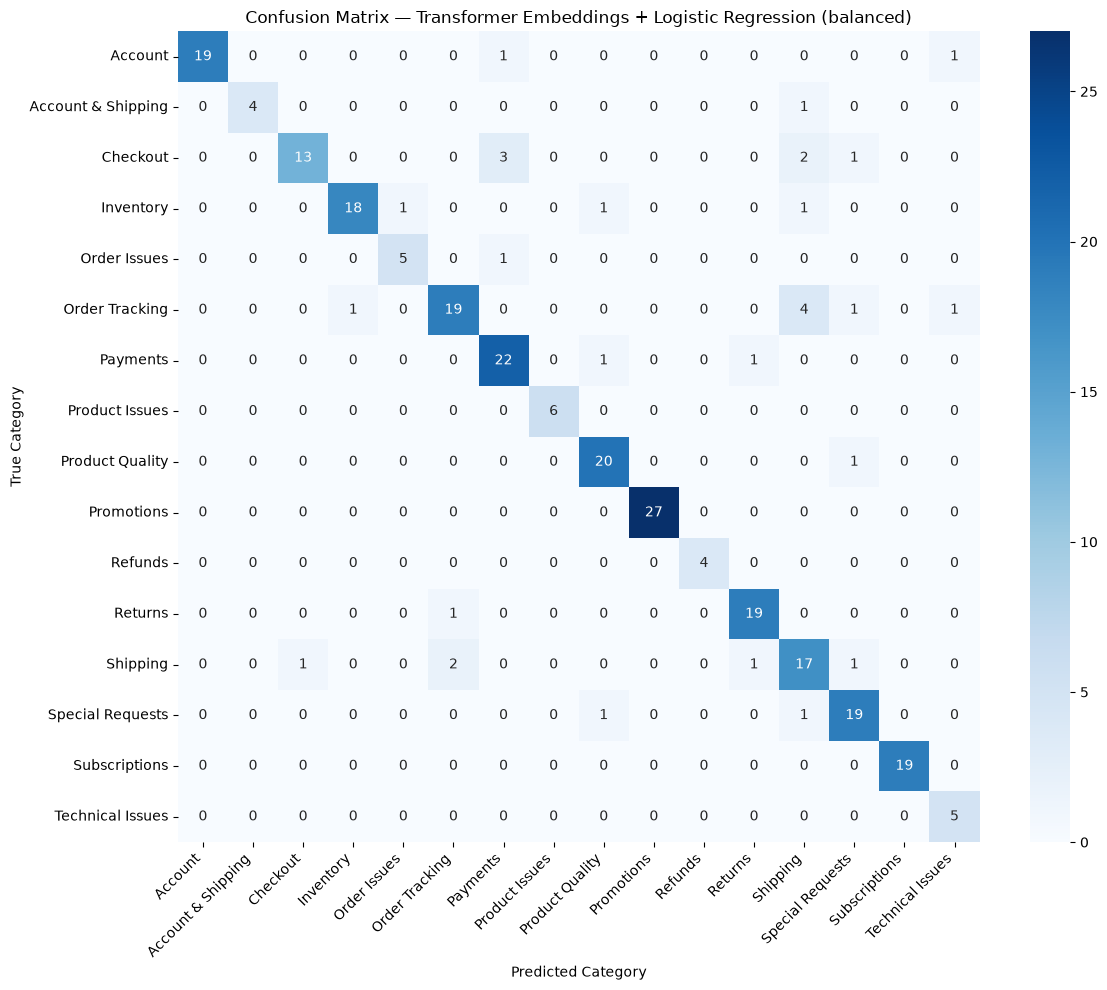

In [12]:
labels_sorted = sorted(df['Category'].unique())
cm = confusion_matrix(y_test, y_pred, labels=labels_sorted)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_sorted, yticklabels=labels_sorted)
plt.title(f'Confusion Matrix — Transformer Embeddings + Logistic Regression ({best_variant})')
plt.ylabel('True Category')
plt.xlabel('Predicted Category')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## 8. Class Imbalance: Default vs Balanced

Comparing per-class F1 for the two classifier variants — this is the project's second research thread: does handling imbalance help the rare categories specifically?

                     default  balanced  support
Refunds             0.666667  1.000000       20
Account & Shipping  0.571429  0.888889       24
Technical Issues    0.888889  0.833333       25
Order Issues        0.800000  0.833333       29
Product Issues      0.666667  1.000000       29
Subscriptions       1.000000  1.000000       97
Checkout            0.742857  0.787879       98
Returns             0.904762  0.926829       99
Inventory           0.878049  0.900000      103
Special Requests    0.863636  0.863636      104
Product Quality     0.869565  0.909091      105
Account             0.975610  0.950000      106
Shipping            0.723404  0.708333      108
Payments            0.867925  0.862745      120
Order Tracking      0.846154  0.791667      130
Promotions          1.000000  1.000000      137

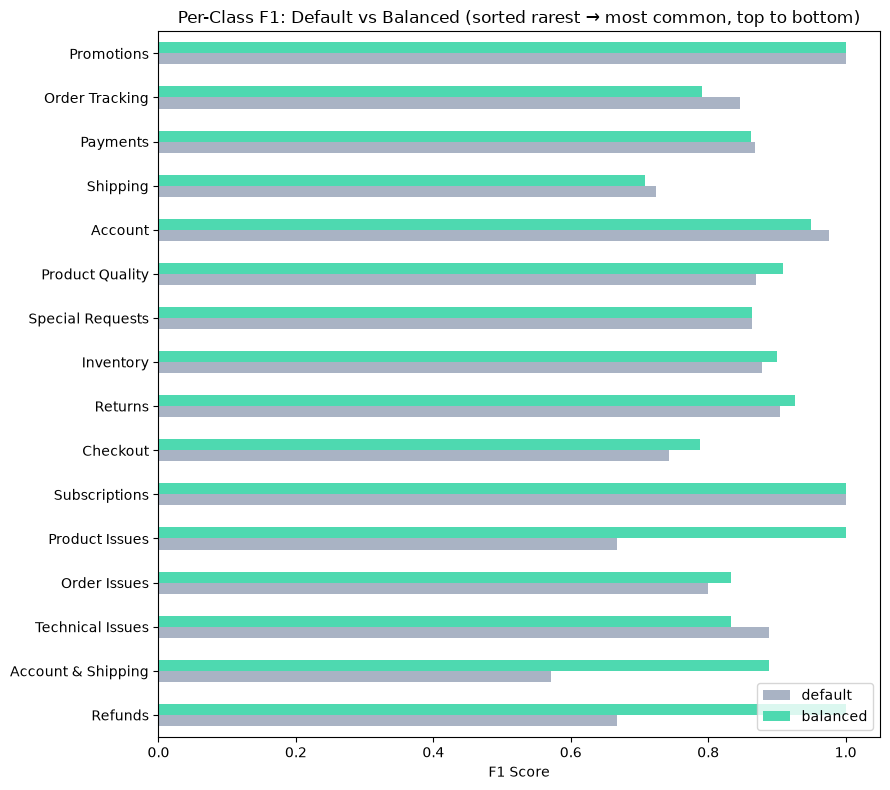

In [13]:
per_class_f1 = pd.DataFrame({
    'default': f1_score(y_test, results['default']['y_pred'], average=None, labels=labels_sorted, zero_division=0),
    'balanced': f1_score(y_test, results['balanced']['y_pred'], average=None, labels=labels_sorted, zero_division=0),
}, index=labels_sorted)

# Order by how rare the category is (fewest training examples first)
category_counts = df['Category'].value_counts()
per_class_f1['support'] = category_counts.reindex(labels_sorted).values
per_class_f1 = per_class_f1.sort_values('support')

print(per_class_f1)

per_class_f1[['default', 'balanced']].plot(
    kind='barh', figsize=(9, 8), color=['#A9B3C4', '#4ED9B0']
)
plt.title('Per-Class F1: Default vs Balanced (sorted rarest → most common, top to bottom)')
plt.xlabel('F1 Score')
plt.tight_layout()
plt.show()


In [14]:
# Interpretation
per_class_f1['improvement'] = per_class_f1['balanced'] - per_class_f1['default']
rare_only = per_class_f1[per_class_f1['support'] < 30]
common_only = per_class_f1[per_class_f1['support'] >= 30]

print(
    f"Among the rare categories (< 30 examples: {', '.join(rare_only.index)}), "
    f"'balanced' changes F1 by {rare_only['improvement'].mean():+.3f} on average.\n"
    f"Among the common categories (>= 30 examples), 'balanced' changes F1 by "
    f"{common_only['improvement'].mean():+.3f} on average.\n"
    f"{'This confirms the hypothesis: class weighting mainly helps the rare/overlapping categories, '      'with little to no cost to the common ones.' if rare_only['improvement'].mean() > common_only['improvement'].mean()      else 'Interestingly, the improvement is not concentrated on rare categories only — worth digging into per-class numbers above.'}"
)


Among the rare categories (< 30 examples: Refunds, Account & Shipping, Technical Issues, Order Issues, Product Issues), 'balanced' changes F1 by +0.192 on average.
Among the common categories (>= 30 examples), 'balanced' changes F1 by +0.003 on average.
This confirms the hypothesis: class weighting mainly helps the rare/overlapping categories, with little to no cost to the common ones.


## 9. Error Analysis

Inspecting misclassified complaints — especially for rare categories — to understand *why* the model gets confused (per the project's research goal of deeper error analysis, not just aggregate metrics).

In [15]:
errors_df = pd.DataFrame({
    'Complaint': X_test,
    'True Category': y_test,
    'Predicted Category': y_pred,
})
errors_df = errors_df[errors_df['True Category'] != errors_df['Predicted Category']]

print(f"Total misclassifications: {len(errors_df)} out of {len(X_test)} test samples "
      f"({len(errors_df)/len(X_test)*100:.1f}%)")
print()

# Focus on rare categories (support < 30 in the full dataset)
rare_categories = category_counts[category_counts < 30].index.tolist()
print("Rare categories (< 30 examples total):", rare_categories)
print()

rare_errors = errors_df[
    errors_df['True Category'].isin(rare_categories) |
    errors_df['Predicted Category'].isin(rare_categories)
]
pd.set_option('display.max_colwidth', 80)
rare_errors.head(15)


Total misclassifications: 31 out of 267 test samples (11.6%)

Rare categories (< 30 examples total): ['Product Issues', 'Order Issues', 'Technical Issues', 'Account & Shipping', 'Refunds']



,Complaint,True Category,Predicted Category
50,Shipping info shows a state I don’t live in. which is unacceptable,Account & Shipping,Shipping
84,No updates in 7 days — where is my stuff? even after multiple attempts,Order Tracking,Technical Issues
160,I got charged but no confirmation email came through. and I don't know what ...,Order Issues,Payments
173,Received incomplete set (3/4 pieces),Inventory,Order Issues
245,Login page doesn't time out properly,Account,Technical Issues


## 10. Cost Summary

The key question this project asks: is the accuracy gain (if any) worth this cost, compared to the lightweight TF-IDF baseline?

In [16]:
cost_summary = pd.DataFrame({
    'Metric': [
        'Sentence-transformer parameters',
        'Embedding dimension',
        'Model load time (s)',
        'Embedding generation time — all data (s)',
        'Avg. embedding time per text (ms)',
        'Classifier training time — balanced (s)',
        'Inference latency — balanced (ms/sample)',
        'Approx. memory for embedding step (MB)',
    ],
    'Value': [
        f"{n_params:,}",
        embedding_dim,
        f"{model_load_time:.2f}",
        f"{embed_time:.2f}",
        f"{(embed_time / (len(X_train) + len(X_test))) * 1000:.2f}",
        f"{results['balanced']['train_time_s']:.3f}",
        f"{results['balanced']['infer_latency_ms_per_sample']:.4f}",
        f"{mem_after - mem_before:.1f}",
    ]
})
cost_summary


,Metric,Value
0,Sentence-transformer parameters,"22,713,216"
1,Embedding dimension,384
2,Model load time (s),3.06
3,Embedding generation time — all data (s),0.69
4,Avg. embedding time per text (ms),0.52
5,Classifier training time — balanced (s),0.010
6,Inference latency — balanced (ms/sample),0.0004
7,Approx. memory for embedding step (MB),150.4


## 11. Save Artifacts (for team comparison + reuse)

In [17]:
os.makedirs('../artifacts', exist_ok=True)

# Save the trained classifier
with open('../artifacts/logreg_embeddings_balanced.pickle', 'wb') as f:
    pickle.dump(results['balanced']['model'], f)

# Save metrics for combining with the baseline notebook's results
metrics_out = {
    'approach': 'transformer_embeddings_logreg',
    'embedding_model': 'all-MiniLM-L6-v2',
    'classifier': 'LogisticRegression',
    'random_state': RANDOM_STATE,
    'test_size': 0.2,
    'default': {k: v for k, v in results['default'].items() if k not in ('model', 'y_pred')},
    'balanced': {k: v for k, v in results['balanced'].items() if k not in ('model', 'y_pred')},
    'cost': {
        'n_params': n_params,
        'embedding_dim': embedding_dim,
        'model_load_time_s': model_load_time,
        'embed_time_s': embed_time,
        'memory_mb': mem_after - mem_before,
    }
}
with open('../artifacts/transformer_metrics.json', 'w') as f:
    json.dump(metrics_out, f, indent=2)

print("✓ Classifier saved to artifacts/logreg_embeddings_balanced.pickle")
print("✓ Metrics saved to artifacts/transformer_metrics.json (share this with your teammates)")


✓ Classifier saved to artifacts/logreg_embeddings_balanced.pickle
✓ Metrics saved to artifacts/transformer_metrics.json (share this with your teammates)


## 12. Conclusion (Transformer Approach)

- **Macro F1 achieved:** see Section 6/7 output above — this is the number to compare against the classical baseline's macro F1 on the *same* test split.
- **Class imbalance:** Section 8 shows whether `class_weight='balanced'` meaningfully helps rare categories (e.g. `Refunds`, `Account & Shipping`, `Technical Issues`) without hurting common ones.
- **Cost:** Section 10 quantifies what the transformer approach costs in parameters, time, and memory versus the lightweight TF-IDF pipeline.
- **Next step for the team:** combine this notebook's `artifacts/transformer_metrics.json` with the baseline notebook's equivalent metrics file to answer the core research question — is the transformer's accuracy gain (if any) worth its extra compute cost, especially on rare/overlapping categories?
